In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [25]:
#IMPORTS
%config Completer.use_jedi = False
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import missingno as msno

from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
import xgboost as xgb
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from joblib import dump, load

from sklearn.model_selection import KFold
from sklearn.feature_selection import RFECV

%matplotlib inline

______________________________________________________________________________________________________________________________
Dataset pre-processed
______________________________________________________________________________________________________________________________

In [3]:
#dataframe from Nicolas + more severe preprocessing (70% of raw df)
df=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/001b_df_processed_nogps.csv')
df['date'] = pd.to_datetime(df.date)

______________________________________________________________________________________________________________________________
target + data
______________________________________________________________________________________________________________________________

data/target

In [4]:
target=df.grav #target
target=target.apply(lambda x: 1 if (x==2 or x==3) else 0)
data=df.drop(['grav','num_veh','date','Num_Acc'],axis=1) #données

split data

In [5]:
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.3,stratify=target)

#cible déséquilibrée alors on fait un under sampling (et ca réduit le data pour tourner plus rapidement)
rus = RandomUnderSampler()
X_ru, y_ru = rus.fit_resample(X_train, y_train)

DNN

In [6]:
from tensorflow.keras.layers import Input, Dense #Pour instancier une couche Dense et une d'Input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# DNN01
basic param

In [7]:
inputs = Input(shape = 92, name = "Input")

dense1 = Dense(units = 32, activation = "tanh", kernel_initializer ='normal', name = "Dense_1")
dense2 = Dense(units = 1, activation = "sigmoid", kernel_initializer ='normal', name = "Dense_4")

x=dense1(inputs)
outputs=dense2(x)

model = Model(inputs = inputs, outputs = outputs)

In [8]:
model.compile(loss = "binary_crossentropy",
              optimizer = "adam",
              metrics = ["accuracy"])

DNN01=model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'),epochs=20,batch_size=32,validation_split=0.2)

Epoch 1/20
12937/12937 [==============================] - 43s 3ms/step - loss: 0.4804 - accuracy: 0.7639 - val_loss: 0.6685 - val_accuracy: 0.6532
Epoch 2/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4676 - accuracy: 0.7728 - val_loss: 0.6631 - val_accuracy: 0.6607
Epoch 3/20
12937/12937 [==============================] - 37s 3ms/step - loss: 0.4645 - accuracy: 0.7748 - val_loss: 0.7548 - val_accuracy: 0.6150
Epoch 4/20
12937/12937 [==============================] - 41s 3ms/step - loss: 0.4627 - accuracy: 0.7763 - val_loss: 0.7286 - val_accuracy: 0.6240
Epoch 5/20
12937/12937 [==============================] - 52s 4ms/step - loss: 0.4613 - accuracy: 0.7765 - val_loss: 0.6966 - val_accuracy: 0.6372
Epoch 6/20
12937/12937 [==============================] - 27s 2ms/step - loss: 0.4605 - accuracy: 0.7775 - val_loss: 0.6641 - val_accuracy: 0.6568
Epoch 7/20
12937/12937 [==============================] - 37s 3ms/step - loss: 0.4598 - accuracy: 0.7782 - val_loss: 0

In [9]:
dump(DNN01, '/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN01.joblib')
# DNN01 = load('/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN01.joblib')

['/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN01.joblib']

In [ ]:
dnn=DNN01

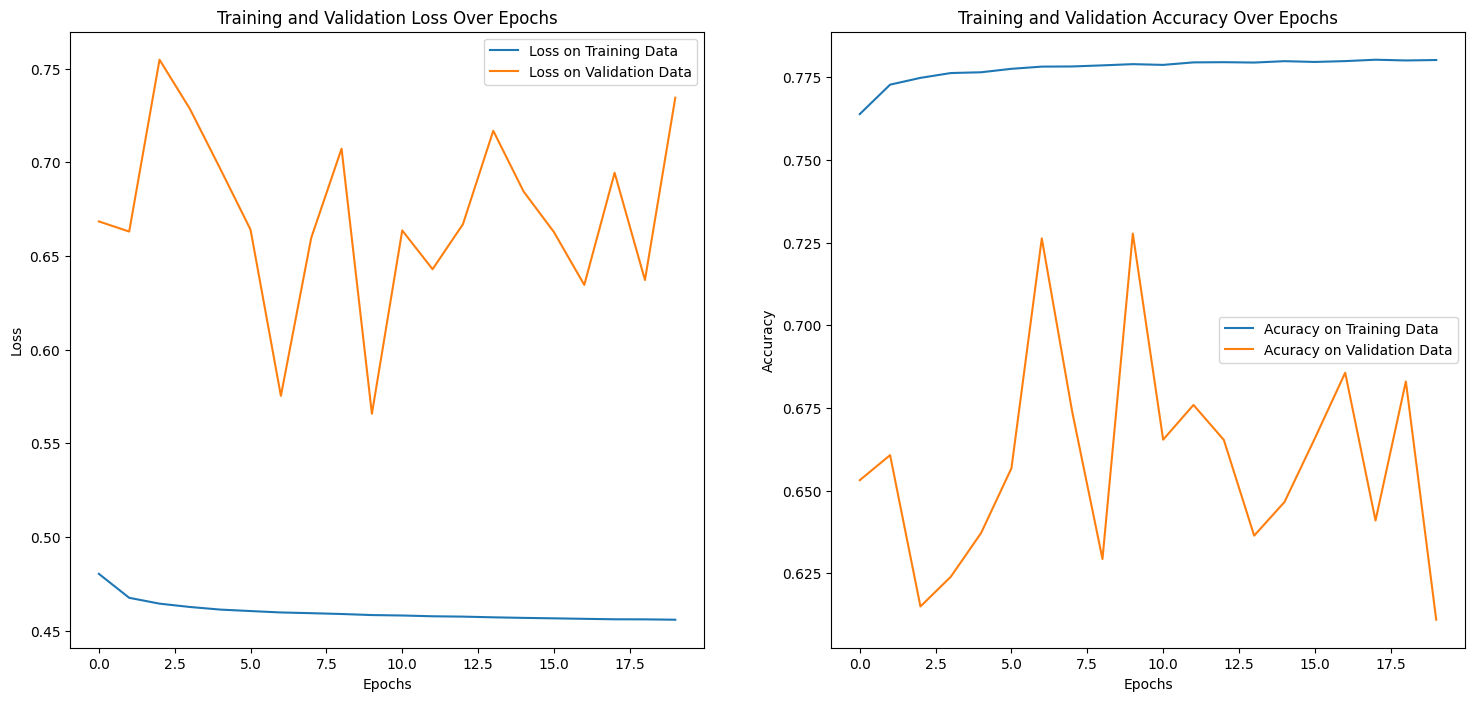

In [13]:
#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [15]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 33s 2ms/step
Classe prédite       0      1
Classe réelle                
0               376052  54377
1                42800  68086
              precision    recall  f1-score   support

           0       0.90      0.87      0.89    430429
           1       0.56      0.61      0.58    110886

    accuracy                           0.82    541315
   macro avg       0.73      0.74      0.73    541315
weighted avg       0.83      0.82      0.82    541315



# DNN02
relu activation

In [16]:
inputs = Input(shape = 92, name = "Input")

dense1 = Dense(units = 32, activation = "relu", kernel_initializer ='normal', name = "Dense_1") #activation changed
dense2 = Dense(units = 1, activation = "sigmoid", kernel_initializer ='normal', name = "Dense_2") #activation changed

x=dense1(inputs)
outputs=dense2(x)

model = Model(inputs = inputs, outputs = outputs)

model.compile(loss = "binary_crossentropy",
              optimizer = "adam",
              metrics = ["accuracy"])

DNN02=model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'),epochs=20,batch_size=32,validation_split=0.2)

Epoch 1/20
12937/12937 [==============================] - 32s 2ms/step - loss: 0.4798 - accuracy: 0.7644 - val_loss: 0.6155 - val_accuracy: 0.6997
Epoch 2/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4666 - accuracy: 0.7737 - val_loss: 0.6708 - val_accuracy: 0.6542
Epoch 3/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4640 - accuracy: 0.7756 - val_loss: 0.6561 - val_accuracy: 0.6660
Epoch 4/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4625 - accuracy: 0.7762 - val_loss: 0.6249 - val_accuracy: 0.6858
Epoch 5/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4614 - accuracy: 0.7771 - val_loss: 0.6567 - val_accuracy: 0.6701
Epoch 6/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4604 - accuracy: 0.7775 - val_loss: 0.7105 - val_accuracy: 0.6355
Epoch 7/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4597 - accuracy: 0.7780 - val_loss: 0

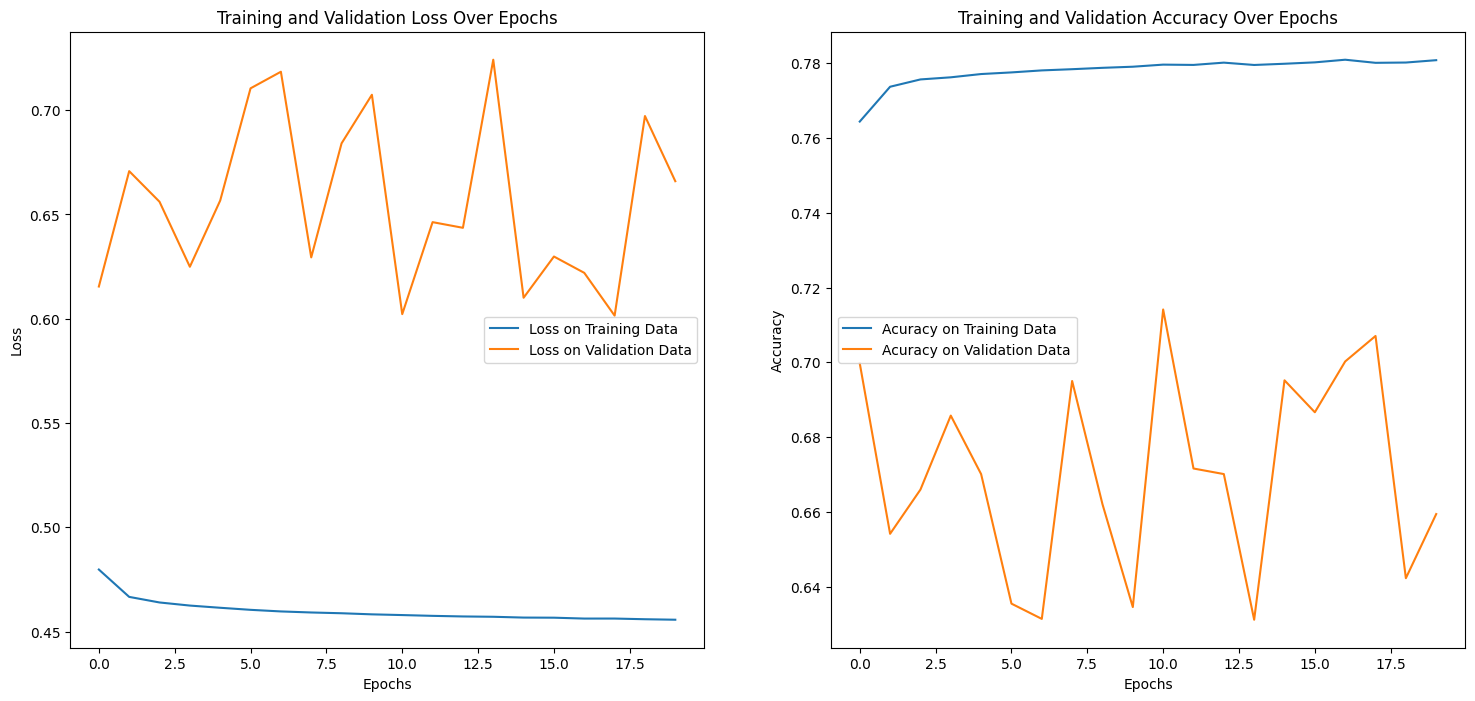

In [17]:
dnn=DNN02

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [21]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 38s 2ms/step
Classe prédite       0      1
Classe réelle                
0               365661  64768
1                37695  73191
              precision    recall  f1-score   support

           0       0.91      0.85      0.88    430429
           1       0.53      0.66      0.59    110886

    accuracy                           0.81    541315
   macro avg       0.72      0.75      0.73    541315
weighted avg       0.83      0.81      0.82    541315



# DNN03 callbacks

In [22]:
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

In [23]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),  # Sauvegarde du meilleur modèle
    EarlyStopping(patience=5),  # Arrêt de l'entraînement anticipé si la perte de validation ne s'améliore pas pendant 5 époques
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)  # Réduit le taux d'apprentissage si la perte de validation stagne
]

inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='normal', name="Dense_1")
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='normal', name="Dense_2")

dense1 = dense1(inputs)
outputs = dense2(dense1)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN04 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 40s 3ms/step - loss: 0.4806 - accuracy: 0.7641 - val_loss: 0.6351 - val_accuracy: 0.6763 - lr: 0.0010
Epoch 2/20
   94/12937 [..............................] - ETA: 21s - loss: 0.4643 - accuracy: 0.7806

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 28s 2ms/step - loss: 0.4685 - accuracy: 0.7725 - val_loss: 0.6252 - val_accuracy: 0.6843 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4653 - accuracy: 0.7746 - val_loss: 0.6362 - val_accuracy: 0.6794 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4635 - accuracy: 0.7755 - val_loss: 0.7061 - val_accuracy: 0.6416 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4623 - accuracy: 0.7767 - val_loss: 0.6495 - val_accuracy: 0.6807 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4584 - accuracy: 0.7787 - val_loss: 0.6591 - val_accuracy: 0.6692 - lr: 1.0000e-04
Epoch 7/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4579 - accuracy: 0.7795 - val_loss: 0.6524 - val_accuracy: 0.6728 - lr: 1.0000e-04


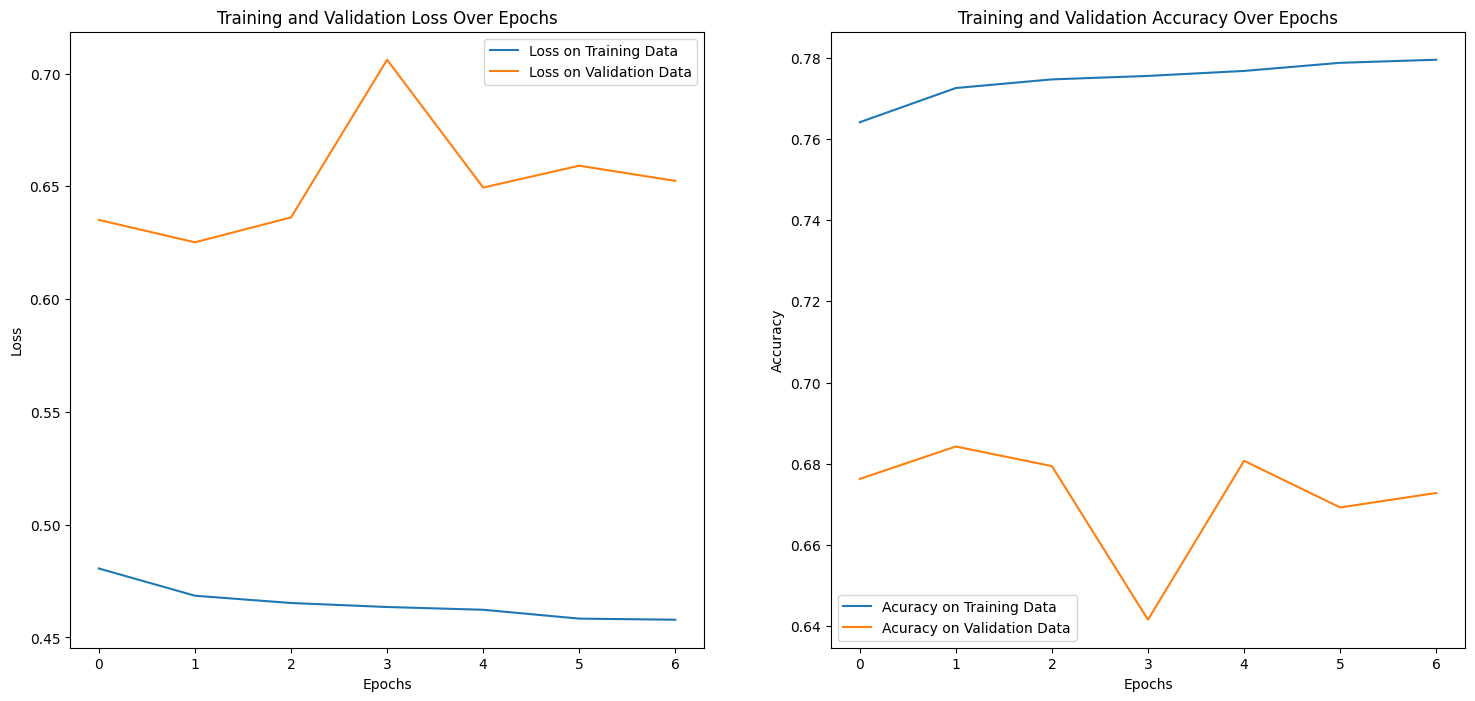

In [24]:
dnn=DNN03

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [26]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 24s 1ms/step
Classe prédite       0      1
Classe réelle                
0               361442  68987
1                36158  74728
              precision    recall  f1-score   support

           0       0.91      0.84      0.87    430429
           1       0.52      0.67      0.59    110886

    accuracy                           0.81    541315
   macro avg       0.71      0.76      0.73    541315
weighted avg       0.83      0.81      0.81    541315



# DNN04 re-test later
kernel_initializer=glorot_normal/he_normal/lecun_normal better for relu

In [31]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),  # Sauvegarde du meilleur modèle
    EarlyStopping(patience=5),  # Arrêt de l'entraînement anticipé si la perte de validation ne s'améliore pas pendant 5 époques
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)  # Réduit le taux d'apprentissage si la perte de validation stagne
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1") #kernel_init changed
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_2") #kernel_init changed

dense1 = dense1(inputs)
outputs = dense2(dense1)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN04 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 31s 2ms/step - loss: 0.4815 - accuracy: 0.7642 - val_loss: 0.6763 - val_accuracy: 0.6480 - lr: 0.0010
Epoch 2/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4690 - accuracy: 0.7717 - val_loss: 0.7380 - val_accuracy: 0.6205 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4657 - accuracy: 0.7744 - val_loss: 0.5540 - val_accuracy: 0.7399 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 27s 2ms/step - loss: 0.4639 - accuracy: 0.7753 - val_loss: 0.5638 - val_accuracy: 0.7276 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4626 - accuracy: 0.7759 - val_loss: 0.6627 - val_accuracy: 0.6677 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4617 - accuracy: 0.7768 - val_loss: 0.7008 - val_accuracy: 0.6289 - lr: 0.0010
Epoch 7/20
12937/12937 [================

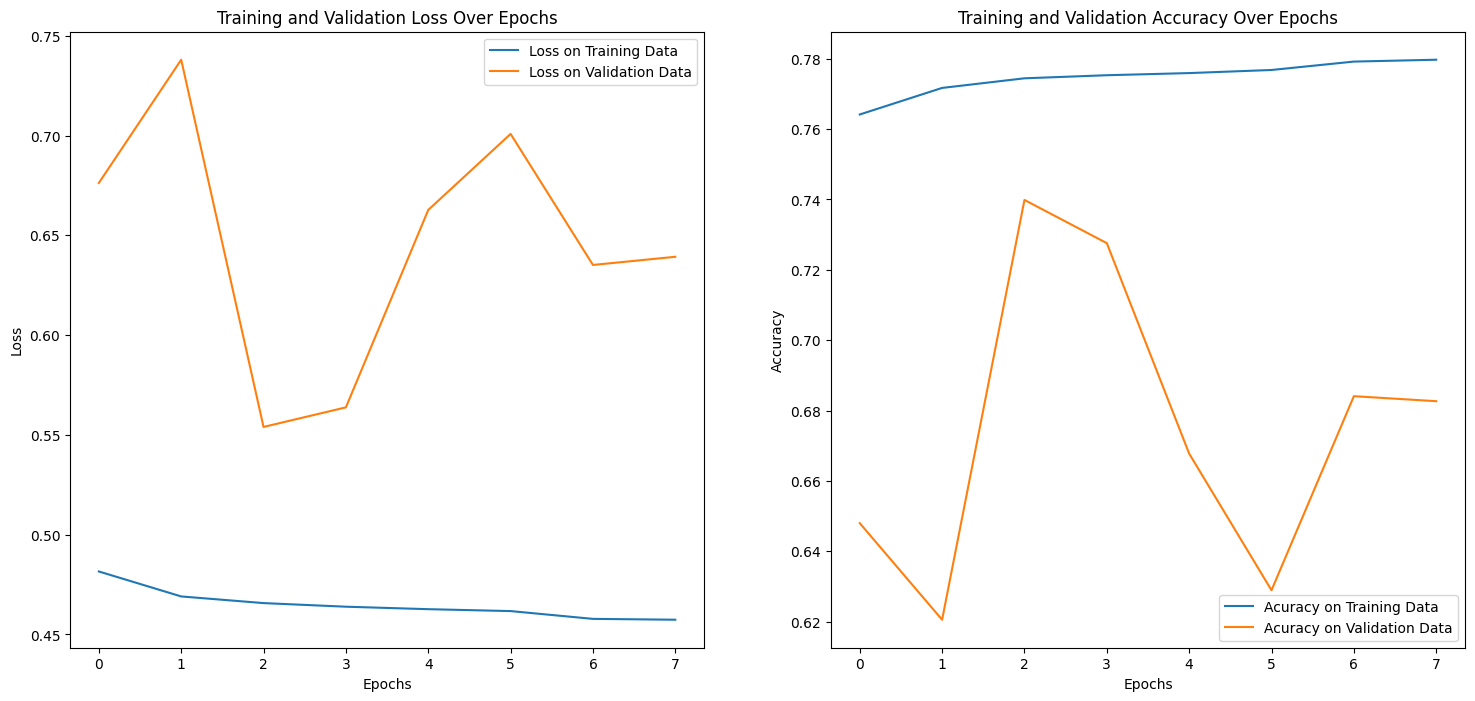

In [32]:
dnn=DNN04

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [33]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 24s 1ms/step
Classe prédite       0      1
Classe réelle                
0               358834  71595
1                35141  75745
              precision    recall  f1-score   support

           0       0.91      0.83      0.87    430429
           1       0.51      0.68      0.59    110886

    accuracy                           0.80    541315
   macro avg       0.71      0.76      0.73    541315
weighted avg       0.83      0.80      0.81    541315



# DNN05
Dropout: technique de régularisation efficace pour les DNN car elle aide à prévenir le surapprentissage en réduisant la dépendance excessive aux données d'entraînement, améliorant ainsi la capacité du modèle à généraliser sur de nouvelles données

In [37]:
from tensorflow.keras.layers import Dropout

In [39]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),
    EarlyStopping(patience=5),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer = Dropout(0.5) #dropout layer
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_2")

dense1 = dense1(inputs)
dropout=dropout_layer(dense1) #dropout layer
outputs = dense2(dropout)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN05 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.5072 - accuracy: 0.7533 - val_loss: 0.6910 - val_accuracy: 0.6113 - lr: 0.0010
Epoch 2/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4896 - accuracy: 0.7620 - val_loss: 0.6231 - val_accuracy: 0.6765 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4877 - accuracy: 0.7636 - val_loss: 0.6859 - val_accuracy: 0.6517 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4858 - accuracy: 0.7654 - val_loss: 0.6793 - val_accuracy: 0.6510 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4852 - accuracy: 0.7657 - val_loss: 0.7319 - val_accuracy: 0.6116 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4821 - accuracy: 0.7683 - val_loss: 0.6692 - val_accuracy: 0.6514 - lr: 1.0000e-04
Epoch 7/20
12937/12937 [============

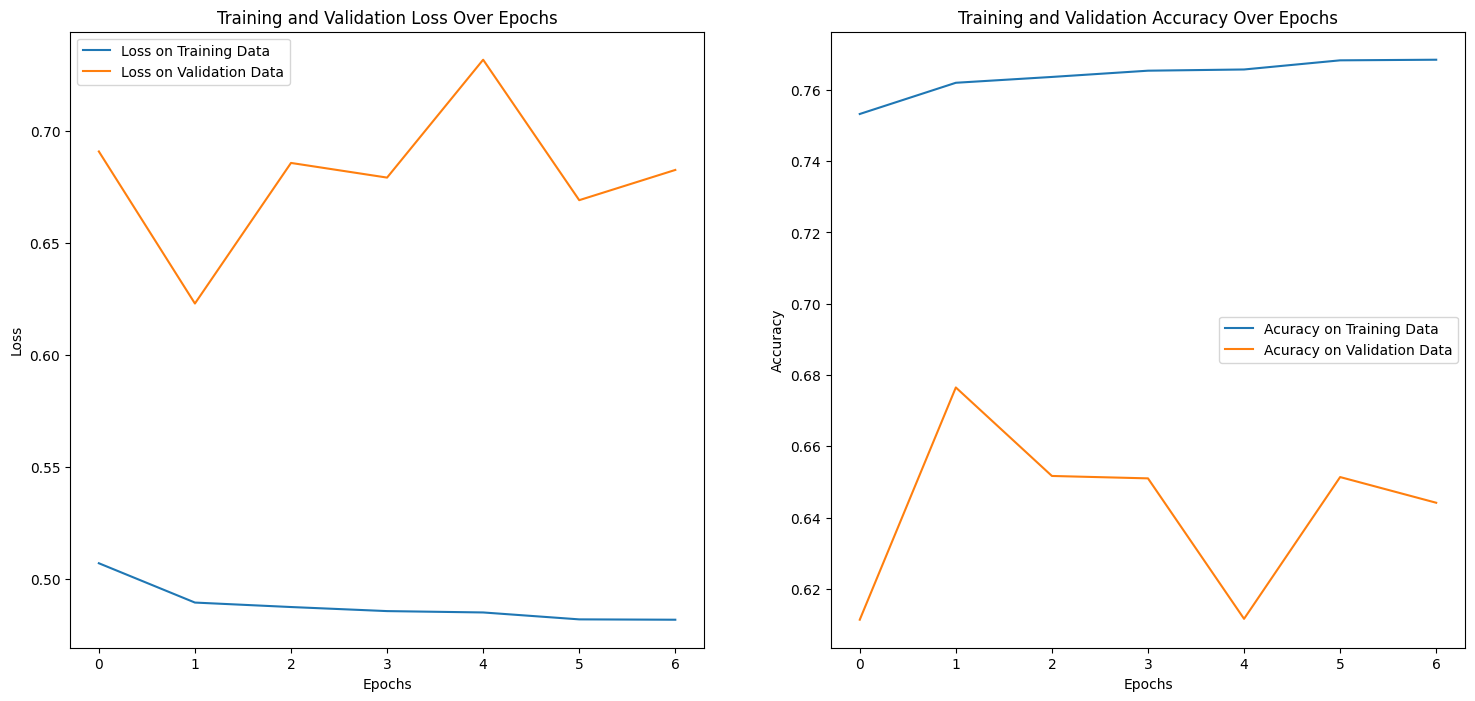

In [40]:
dnn=DNN05

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [41]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 24s 1ms/step
Classe prédite       0      1
Classe réelle                
0               365830  64599
1                39306  71580
              precision    recall  f1-score   support

           0       0.90      0.85      0.88    430429
           1       0.53      0.65      0.58    110886

    accuracy                           0.81    541315
   macro avg       0.71      0.75      0.73    541315
weighted avg       0.83      0.81      0.81    541315



# DNN06 more layers

In [42]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),  # Sauvegarde du meilleur modèle
    EarlyStopping(patience=5),  # Arrêt de l'entraînement anticipé si la perte de validation ne s'améliore pas pendant 5 époques
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)  # Réduit le taux d'apprentissage si la perte de validation stagne
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer1 = Dropout(0.5) #dropout layer
dense2 = Dense(units=16, activation="relu", kernel_initializer='glorot_normal', name="Dense_2")
dropout_layer2 = Dropout(0.5) #dropout layer
dense3 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_3")

dense1 = dense1(inputs)
dropout1=dropout_layer1(dense1) #dropout layer
dense2=dense2(dropout1) #new layer
dropout2=dropout_layer2(dense2) #dropout layer
outputs = dense3(dropout2)



model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN06 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 32s 2ms/step - loss: 0.5378 - accuracy: 0.7263 - val_loss: 0.7575 - val_accuracy: 0.5624 - lr: 0.0010
Epoch 2/20
   57/12937 [..............................] - ETA: 35s - loss: 0.5243 - accuracy: 0.7336

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 32s 2ms/step - loss: 0.5123 - accuracy: 0.7462 - val_loss: 0.6651 - val_accuracy: 0.6410 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 32s 3ms/step - loss: 0.5096 - accuracy: 0.7511 - val_loss: 0.7311 - val_accuracy: 0.5707 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 32s 3ms/step - loss: 0.5077 - accuracy: 0.7530 - val_loss: 0.6764 - val_accuracy: 0.6377 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 33s 3ms/step - loss: 0.5072 - accuracy: 0.7546 - val_loss: 0.6985 - val_accuracy: 0.5940 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 32s 2ms/step - loss: 0.5035 - accuracy: 0.7577 - val_loss: 0.6940 - val_accuracy: 0.6127 - lr: 1.0000e-04
Epoch 7/20
12937/12937 [==============================] - 33s 3ms/step - loss: 0.5028 - accuracy: 0.7580 - val_loss: 0.6972 - val_accuracy: 0.6001 - lr: 1.0000e-04


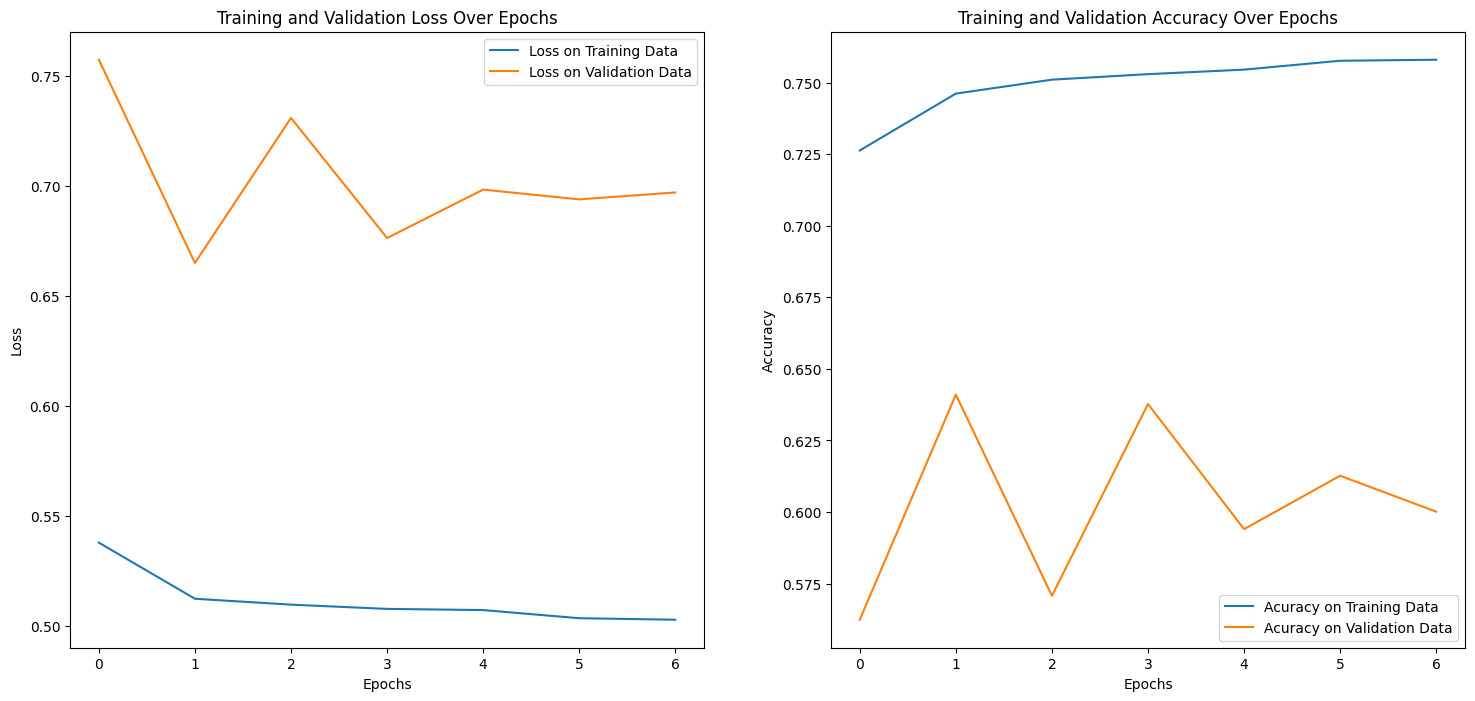

In [43]:
dnn=DNN06

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [44]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 24s 1ms/step
Classe prédite       0      1
Classe réelle                
0               373759  56670
1                44286  66600
              precision    recall  f1-score   support

           0       0.89      0.87      0.88    430429
           1       0.54      0.60      0.57    110886

    accuracy                           0.81    541315
   macro avg       0.72      0.73      0.72    541315
weighted avg       0.82      0.81      0.82    541315

